## Model building and Pipelines

Here we will build actual pipeline and model .

In [495]:
from pathlib import Path
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

path=Path.cwd()
file_path=path.parent/'Data'/'cleaned_data.csv'
data=pd.read_csv(file_path)
df=data.copy()
df

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...
9995,M24855,M,298.8,308.4,1604,29.5,14,0
9996,H39410,H,298.9,308.4,1632,31.8,17,0
9997,M24857,M,299.0,308.6,1645,33.4,22,0
9998,H39412,H,299.0,308.7,1408,48.5,25,0


In [496]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, accuracy_score,confusion_matrix
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer


In [497]:
df['MachineFailure'].value_counts()

MachineFailure
0    9661
1     339
Name: count, dtype: int64

In [498]:
df.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


In [499]:
df.shape

(10000, 8)

In [500]:
X=df.drop(columns=['MachineFailure', 'Product ID'],axis=1)
y=df['MachineFailure']

In [501]:
X

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14
9996,H,298.9,308.4,1632,31.8,17
9997,M,299.0,308.6,1645,33.4,22
9998,H,299.0,308.7,1408,48.5,25


In [502]:
X_train,X_test,y_train,y_test=train_test_split(X,y , test_size=0.2, random_state=42,stratify=y)

In [503]:
X_train.shape, y_train.shape

((8000, 6), (8000,))

In [504]:
X_test.shape,y_test.shape

((2000, 6), (2000,))

In [505]:
numerical_cols=X.select_dtypes(include=np.number).columns.tolist()
numerical_cols

['Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]']

In [506]:
# we will not take product_id as it is just an unique identifier . 
categorical_col=X.select_dtypes(exclude=np.number).columns.tolist()
categorical_col

['Type']

In [507]:
# scale and encode 

preprocess=ColumnTransformer(transformers=[('num',StandardScaler(),numerical_cols),
                                           ('category',OneHotEncoder(sparse_output=False, handle_unknown='ignore'),categorical_col)],remainder='drop')
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e

In [508]:
# we will see and experiment with diffrent models ,so for that we will use manually 

X_train_transform=preprocess.fit_transform(X_train)
X_test_transform=preprocess.transform(X_test)

X_train_transform

array([[ 0.99891359,  0.60428162, -0.46060741, ...,  0.        ,
         0.        ,  1.        ],
       [-1.50519408, -1.15325984, -0.77557391, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.49809206,  1.07746586, -1.00765448, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 0.14751698,  1.00986812, -0.41640159, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.84866713,  0.80707487, -0.12353801, ...,  0.        ,
         1.        ,  0.        ],
       [-0.65379747, -0.20689136, -0.42745305, ...,  0.        ,
         1.        ,  0.        ]], shape=(8000, 8))

### Solving Class Imbalance and Testing

In [509]:
# 1 . Class weight approach 

In [510]:
classweight=[
    'balanced',
    {0: 1, 1: 5},
    {0: 1, 1: 10},
    {0: 1, 1: 20},
    {0: 1, 1: 40},
]

result=[]

# logistic reg:
for x in classweight:
    lr=LogisticRegression(class_weight=x)
    lr.fit(X_train_transform,y_train)
    pred=lr.predict(X_test_transform)
    result.append({
            'class weight':str(x),
            "accuracy:":accuracy_score(y_test,pred),
            'precision_score':precision_score(y_test,pred),
            'recall_Score': recall_score(y_test,pred)
    })

result_df1=pd.DataFrame(result)
result_df1

,class weight,accuracy:,precision_score,recall_Score
0,balanced,0.8245,0.141772,0.823529
1,"{0: 1, 1: 5}",0.9580,0.406977,0.514706
2,"{0: 1, 1: 10}",0.9285,0.272727,0.661765
3,"{0: 1, 1: 20}",0.8740,0.180556,0.764706
4,"{0: 1, 1: 40}",0.7705,0.118908,0.897059


{0: 1, 1: 5}	0.9580	0.406977	0.514706

In [511]:
 # decision tree 
classweight2=[
    'balanced',
    {0: 1, 1: 5},
    {0: 1, 1: 10},
    {0: 1, 1: 20},
    {0: 1, 1: 40},
]

result_dt=[]

# decision tree:
for x in classweight2:
    lr=DecisionTreeClassifier(class_weight=x)
    lr.fit(X_train_transform,y_train)
    pred=lr.predict(X_test_transform)
    result_dt.append({
            'class weight':str(x),
            "accuracy:":accuracy_score(y_test,pred),
            'precision_score':precision_score(y_test,pred),
            'recall_Score': recall_score(y_test,pred)
    })

result_df2=pd.DataFrame(result_dt)
result_df2

,class weight,accuracy:,precision_score,recall_Score
0,balanced,0.9795,0.736842,0.617647
1,"{0: 1, 1: 5}",0.9810,0.734375,0.691176
2,"{0: 1, 1: 10}",0.9775,0.671642,0.661765
3,"{0: 1, 1: 20}",0.9790,0.709677,0.647059
4,"{0: 1, 1: 40}",0.9780,0.700000,0.617647


for weights = {0: 1, 1: 5} logistic regression's best was  :
	
- Accuracy: 0.9580	
- precision: 0.406977	
- recall : 0.514706



in class weight Decision tree has given better performance with :
- Accuracy of 98% 
-  precesion around 74% 
-  recall around 67% . 

so , the D.T with class wt 1:5 is the candidate till now 



In [512]:
# 2 . undersampling 

from imblearn.under_sampling import RandomUnderSampler

under=RandomUnderSampler(sampling_strategy='auto',random_state=42)

# undersample - take out the data from maj class so that it becoms equal to minority class
X_train_under, y_train_under=under.fit_resample(X_train_transform,y_train)
print('\nTotal classes:')
print(df['MachineFailure'].value_counts())
print()

print("\nBefore:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_under.value_counts())



Total classes:
MachineFailure
0    9661
1     339
Name: count, dtype: int64


Before:
MachineFailure
0    7729
1     271
Name: count, dtype: int64

After:
MachineFailure
0    271
1    271
Name: count, dtype: int64


In [513]:
# now we have under sampled label now lets train decsion tree and see the resuls 
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train_under, y_train_under)

pred_under = dt.predict(X_test_transform)

print("Accuracy:", accuracy_score(y_test, pred_under))
print("Precision:", precision_score(y_test, pred_under))
print("Recall:", recall_score(y_test, pred_under))

Accuracy: 0.897
Precision: 0.2366412213740458
Recall: 0.9117647058823529


In [514]:
# Oversampling -> Duplicate minority with majority till it becomes equal to the majority class 

from imblearn.over_sampling import RandomOverSampler

over=RandomOverSampler(sampling_strategy='auto',random_state=42)
X_train_over, y_train_over=over.fit_resample(X_train_transform,y_train)


print("\nBefore:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_over.value_counts())



Before:
MachineFailure
0    7729
1     271
Name: count, dtype: int64

After:
MachineFailure
0    7729
1    7729
Name: count, dtype: int64


In [515]:

# now we have over sampled label now lets train decsion tree and see the resuls 
dt_over = DecisionTreeClassifier(random_state=42)

dt_over.fit(X_train_over, y_train_over)

pred_over = dt_over.predict(X_test_transform)

print("Accuracy:", accuracy_score(y_test, pred_over))
print("Precision:", precision_score(y_test, pred_over))
print("Recall:", recall_score(y_test, pred_over))

Accuracy: 0.9785
Precision: 0.7358490566037735
Recall: 0.5735294117647058


we have for under sampling :
- Accuracy: 0.897
- Precision: 0.2366412213740458
- Recall: 0.9117647058823529

we have for over sampling :

- Accuracy: 0.9785
- Precision: 0.7358490566037735
- Recall: 0.5735294117647058



but over sampling has chances to overfit as we duplicate the data .. 


we  have for class-weight:

- Accuracy: 0.9820
- Precision:  0.741935	
- Recall:  0.676471


> 
>> The over sampling and under sampling technique couldn't beat the Decsion Tree class weight's performance .
So the D.T with choose class weight is still ahead 


In [516]:
# SMOTE - Extension of over sampling , instead of duplicating we generate data . 

from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_transform,
    y_train
)



print("Before:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before:
MachineFailure
0    7729
1     271
Name: count, dtype: int64

After SMOTE:
MachineFailure
0    7729
1    7729
Name: count, dtype: int64


In [517]:
dt_smote = DecisionTreeClassifier(random_state=42)

dt_smote.fit(X_train_smote, y_train_smote)

pred_smote = dt_smote.predict(X_test_transform)

print("Accuracy:", accuracy_score(y_test, pred_smote))
print("Precision:", precision_score(y_test, pred_smote))
print("Recall:", recall_score(y_test, pred_smote))


# SMOTE only applied to training data 

Accuracy: 0.9615
Precision: 0.45871559633027525
Recall: 0.7352941176470589


In [518]:
# SMOTENC- same like SMOTE works for both numerical and categorical features 

# It require categorical to be idenfitied as categorical not encoded numerical col 



In [519]:
X

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14
9996,H,298.9,308.4,1632,31.8,17
9997,M,299.0,308.6,1645,33.4,22
9998,H,299.0,308.7,1408,48.5,25


In [520]:
# SMOTENC- same like SMOTE works for both numerical and categorical features 

# It require categorical to be idenfitied as categorical not encoded numerical col 
from imblearn.over_sampling import SMOTENC

cat_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_col
]

smotenc = SMOTENC(
    categorical_features=cat_indices,
    sampling_strategy='auto',
    random_state=42
)
 # use col that is not encoded so we will make use of xtrain which is just splitted 
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(X_train, y_train)

In [521]:
X_train_transform_smotenc = preprocess.fit_transform(X_train_smotenc)

X_test_transform_smotenc = preprocess.transform(X_test)

In [522]:
dt_smotenc = DecisionTreeClassifier(random_state=42)

dt_smotenc.fit(X_train_transform_smotenc,y_train_smotenc)

pred_smotenc = dt_smotenc.predict(
    X_test_transform_smotenc
)

print("Accuracy:", accuracy_score(y_test, pred_smotenc))
print("Precision:", precision_score(y_test, pred_smotenc))
print("Recall:", recall_score(y_test, pred_smotenc))



Accuracy: 0.9475
Precision: 0.362962962962963
Recall: 0.7205882352941176


we have for under sampling :
- Accuracy: 0.897
- Precision: 0.2366412213740458
- Recall: 0.9117647058823529

we have for over sampling :

- Accuracy: 0.9785
- Precision: 0.7358490566037735
- Recall: 0.5735294117647058



but over sampling has chances to overfit as we duplicate the data .. 


we  have for class-weight:

- Accuracy: 0.9820
- Precision: 0.676471
- Recall: 0.76667






we have for SMOTENC:

we have for under sampling :
- Accuracy: 0.897
- Precision: 0.2366412213740458
- Recall: 0.9117647058823529

we have for over sampling :

- Accuracy: 0.9785
- Precision: 0.7358490566037735
- Recall: 0.5735294117647058



but over sampling has chances to overfit as we duplicate the data .. 


we  have for class-weight:

- Accuracy: 0.9820
- Precision: 0.676471
- Recall: 0.76667



we have for SMOTE:
- Accuracy: 0.9615
- Precision: 0.45871559633027525
- Recall: 0.7352941176470589




we have for SMOTENC:
- Accuracy: 0.9475
- Precision: 0.362962962962963
- Recall: 0.7205882352941176
> looking at the over all metrices we could still argubly choose class-weight method for the imbalance dataset solution. 

##### So, to solve the imbalnce dataset problem we will use the Decision Tree , and the class weight 0:1 and 1:5 will be used in pipeline which gives : 
- Accuracy of  around 98% 
-  precesion around 0.730159	
-  recall around 0.676471 


#### Experiment with Ensemble techniques 

In [523]:
''' Bagging - we will use diffrent baseline model and create a big ensemble model . we choose the model that
is low bias and high variance as baggging helps to achive low bias low variance model. so , we will go with 
decision tree '''

# we will also make use of class-weight as we have determined it is the best one for solving imbalaced data 

from sklearn.ensemble import BaggingClassifier

bag=BaggingClassifier(estimator=DecisionTreeClassifier(class_weight={0: 1, 1: 5},random_state=42),
                      bootstrap=True, n_estimators=4)
# we didin't use bunch of parameters as we will have to tune it and use then . 


bag.fit(X_train_transform,y_train)
bag_pred=bag.predict(X_test_transform)
print('accuracy:',accuracy_score(y_test,bag_pred))
print('recall:',recall_score(y_test,bag_pred))
print('precision:',precision_score(y_test,bag_pred))

accuracy: 0.985
recall: 0.6470588235294118
precision: 0.88


In [524]:
confusion_matrix(y_test,bag_pred)

array([[1926,    6],
       [  24,   44]])

 ### There are two types of mistakes:
1. False Negative (FN): The machine is actually going to fail, but your model predicts that it won't. This is dangerous because maintenance may not happen in time.
2. False Positive (FP): The machine is perfectly fine, but your model predicts that it will fail. This can lead to unnecessary inspections or maintenance costs.

-

##### In predictive maintenance, missing an actual machine failure can be more expensive than conducting an unnecessary inspection. That's why recall is generally the priority.

In [525]:
#Bagging 


from sklearn.ensemble import RandomForestClassifier

# now we will used the encoded and scaled dataset freely 


rf=RandomForestClassifier(random_state=42,n_estimators=100)
rf.fit(X_train_transform,y_train)
rf_pred=rf.predict(X_test_transform)
accuracy_score(y_test,rf_pred)

0.9815

In [526]:
confusion_matrix(y_test,rf_pred,labels=[1,0])

array([[  35,   33],
       [   4, 1928]])

In [527]:
print('recall',recall_score(y_test,rf_pred))
print('precision',precision_score(y_test,rf_pred))

recall 0.5147058823529411
precision 0.8974358974358975


In [528]:
# Boosting 


from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier


In [529]:
# Ada-boost


ada=AdaBoostClassifier(n_estimators=5, learning_rate=0.5,random_state=42)
ada.fit(X_train_transform,y_train)
ada_pred=ada.predict(X_test_transform)
print('accuracy:',accuracy_score(y_test,ada_pred))
print('precision:',precision_score(y_test,ada_pred))
print('recall:',recall_score(y_test,ada_pred))

accuracy: 0.969
precision: 0.8
recall: 0.11764705882352941


In [530]:
# gradient-Boost

grad=GradientBoostingClassifier(n_estimators=100)
grad.fit(X_train_transform,y_train)
grad_pred=grad.predict(X_test_transform)
print(accuracy_score(y_test,grad_pred))
print('precision:',precision_score(y_test,grad_pred))
print('recall:',recall_score(y_test,grad_pred))

0.9855
precision: 0.8823529411764706
recall: 0.6617647058823529


In [531]:
# XG boost 


xg=XGBClassifier(n_estimators=100)
xg.fit(X_train_transform,y_train)
xg_pred=xg.predict(X_test_transform)
print(accuracy_score(y_test,xg_pred))
print('precision:',precision_score(y_test,xg_pred))
print('recall:',recall_score(y_test,xg_pred))

0.988
precision: 0.9074074074074074
recall: 0.7205882352941176


XGBoost can perform very well with default parameters, but it absolutely benefits from hyperparameter tuning. Parameters such as max_depth, learning_rate, n_estimators, subsample and colsample_bytree can significantly affect performance.

### Testing and Hyper-parameter Tuning 

In [532]:
from sklearn.model_selection import cross_val_score, RandomizedSearchCV, GridSearchCV,StratifiedKFold,cross_validate
from sklearn.pipeline import make_pipeline


'''StratifiedKfold use
Stratified K-Fold is particularly useful in scenarios where the class distribution is not evenly balanced. 
It helps maintain the original class proportions across folds, which is crucial for accurate model evaluation.
'''

'StratifiedKfold use\nStratified K-Fold is particularly useful in scenarios where the class distribution is not evenly balanced. \nIt helps maintain the original class proportions across folds, which is crucial for accurate model evaluation.\n'

In [533]:
cv=StratifiedKFold(shuffle=True, random_state=42, n_splits=5) # nsplit - divide training data to fold for CV


# xtrain will go through its own pipeline 
# make pipeling auto names each step so less syntax, otherwise same as pipeline()

dt_pipe=make_pipeline(preprocess,DecisionTreeClassifier(class_weight={0:1,1:5},random_state=42))

bag_pipe=make_pipeline(preprocess,BaggingClassifier(estimator=DecisionTreeClassifier(class_weight={0:1,1:5}),random_state=42,n_estimators=50))

rf_pipe=make_pipeline(preprocess,RandomForestClassifier(n_estimators=50,random_state=42))


gb_pipe=make_pipeline(preprocess,GradientBoostingClassifier(random_state=42))


xg_pipe=make_pipeline(preprocess,XGBClassifier(random_state=42))





models={
    'Decison Tree':dt_pipe,
    'Bagging':bag_pipe,
    'Random Forest':rf_pipe,
    'Gradient Boosting':gb_pipe,
    'XGBoost':xg_pipe
}


scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

score_crossvalid={}

for key, value in models.items():
    cv_score=cross_validate(value, X_train,y_train,cv=cv, scoring=scoring,n_jobs=-1)

    score_crossvalid[key]={}

    for metric in scoring:
        scores = cv_score[f'test_{metric}']
       
        score_crossvalid[key][metric]=scores.mean()


In [534]:
cross_df=pd.DataFrame(score_crossvalid).T
cross_df.sort_values(by='recall',ascending=False)


,accuracy,precision,recall,f1
Decison Tree,0.979125,0.699760,0.671785,0.684246
XGBoost,0.982125,0.803416,0.634949,0.706542
Bagging,0.984000,0.884531,0.612727,0.721268
Gradient Boosting,0.983375,0.872507,0.601684,0.708991
Random Forest,0.978750,0.867492,0.442963,0.583190


XG,bagging and gradient are top condidates


 
Function	Purpose: 

- cross_val_score()	Evaluates one metric
- cross_validate()	Evaluates multiple metrics together


### ROC- AUC evluation 

ROC measure the trade of between TPR(Benefit) and FPR(cost)... 

In [535]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
for name, model in models.items():

    y_proba = cross_val_predict( # generate the predection for every sample but from model it didnt train sample
        model,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]

y_proba # probab of each class . 

array([6.6922384e-04, 1.2445122e-04, 1.3803722e-05, ..., 1.0486732e-05,
       2.4779320e-05, 2.3042454e-05], shape=(8000,), dtype=float32)

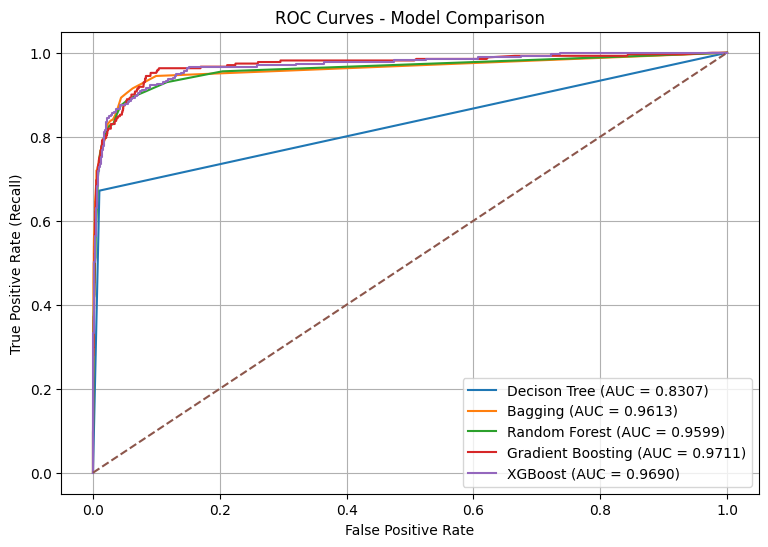

In [536]:


plt.figure(figsize=(9, 6))

for name, model in models.items():

    y_proba = cross_val_predict( # generate the predection for every sample but from model it didnt train sample
        model,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]

    fpr, tpr, thresholds = roc_curve(y_train, y_proba)

    auc_score = roc_auc_score(y_train, y_proba)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--',)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves - Model Comparison')
plt.legend()
plt.grid()
plt.show()

AUC - area under the curve measure the ability of model to seperat the classes across diffrent model . 

AUC has a beautiful interpretation:
It represents the probability that your model will assign a higher score to a randomly selected positive sample than to a randomly selected negative sample.



> 

we know that the predections 1 or 0 are actually not predicted directly by the model . the model actually predecits the probability for each predection . 

say threshod is 0.5 to be a failure then the probabilites which are greater than 0.5 become failure / class 1 . other under the threshld stay as non failure/class 0 . 

> so from the figure we can see that model in red line color in ROC curve has the best benefit TPR . and that its Gradient Boosting . 
The decision tree among other models has less ability to determine more TPR 

- Tpr: how many postivie class model can actually predict correctly.
- FPR - how many negative class model incorrectly predicts as postive. 

so among all the models selected Decsion tree had the least trade off .

likewise for AUC curve , Gradient Boosting , XGBoost and Bagging significantly performed better than D.T and have more ability to rank the diffrence in classes. 

But this dosent mean D.T model is bad and we select those 3 . 



ROC_AUC curve just evlaute model across diffrent threshold .it dosent say which threshold to use and which model is better

D.T peformed a bit low in ROC_AUC compared to other but , here in machine failure as we are prioritizing recall, D.T has the highest recall cross-validated across k folds. 

In [537]:
# threshold comparison of models at diffrent thresholds 

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

selected_models = {
    'Decision Tree': dt_pipe,
    'Bagging': bag_pipe,
    'Gradient Boosting': gb_pipe,
    'XGBoost': xg_pipe,
    'Random Forest':rf_pipe
}

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for name, model in selected_models.items():

    y_proba = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1] #  [:, 1] selects the probability of class 1, which is machine failure.

    for threshold in thresholds:

        y_pred = (y_proba >= threshold).astype(int)

        ''' if y_proba = [0.15, 0.35, 0.48, 0.65, 0.90]
            threshold = 0.5 => if equal of greater to 0.5 then only failure. 
            then it will generate f,f,f,t,t,  
            
            then from .astype we do type casting to int and it become: 0 0 0 1 1 '''

        tn, fp, fn, tp = confusion_matrix(
            y_train, y_pred,
        ).ravel()

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Precision': precision_score(y_train, y_pred, zero_division=0),
            'Recall': recall_score(y_train, y_pred),
            'F1': f1_score(y_train, y_pred, zero_division=0),
            'FPR': fp / (fp + tn)
        })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Model,Threshold,Precision,Recall,F1,FPR
0,Decision Tree,0.2,0.700000,0.671587,0.685499,0.010092
1,Decision Tree,0.3,0.700000,0.671587,0.685499,0.010092
2,Decision Tree,0.4,0.700000,0.671587,0.685499,0.010092
3,Decision Tree,0.5,0.700000,0.671587,0.685499,0.010092
4,Decision Tree,0.6,0.700000,0.671587,0.685499,0.010092
5,Decision Tree,0.7,0.700000,0.671587,0.685499,0.010092
6,Bagging,0.2,0.573643,0.819188,0.674772,0.021348
7,Bagging,0.3,0.697987,0.767528,0.731107,0.011644
8,Bagging,0.4,0.805785,0.719557,0.760234,0.006081
9,Bagging,0.5,0.871287,0.649446,0.744186,0.003364


In [538]:
threshold_df.sort_values(
    by='Recall',
    ascending=False
)

,Model,Threshold,Precision,Recall,F1,FPR
6,Bagging,0.2,0.573643,0.819188,0.674772,0.021348
24,Random Forest,0.2,0.555276,0.815498,0.660688,0.022901
12,Gradient Boosting,0.2,0.673077,0.774908,0.720412,0.013197
7,Bagging,0.3,0.697987,0.767528,0.731107,0.011644
25,Random Forest,0.3,0.715789,0.752768,0.733813,0.010480
18,XGBoost,0.2,0.664474,0.745387,0.702609,0.013197
19,XGBoost,0.3,0.738636,0.719557,0.728972,0.008927
13,Gradient Boosting,0.3,0.780000,0.719557,0.748560,0.007116
8,Bagging,0.4,0.805785,0.719557,0.760234,0.006081
20,XGBoost,0.4,0.769874,0.678967,0.721569,0.007116


In [539]:
##### understand this thign very nicely... again revise roc auc and see this code from roc auc plot 

In [540]:
# Implementing Precision-recall apporach too 

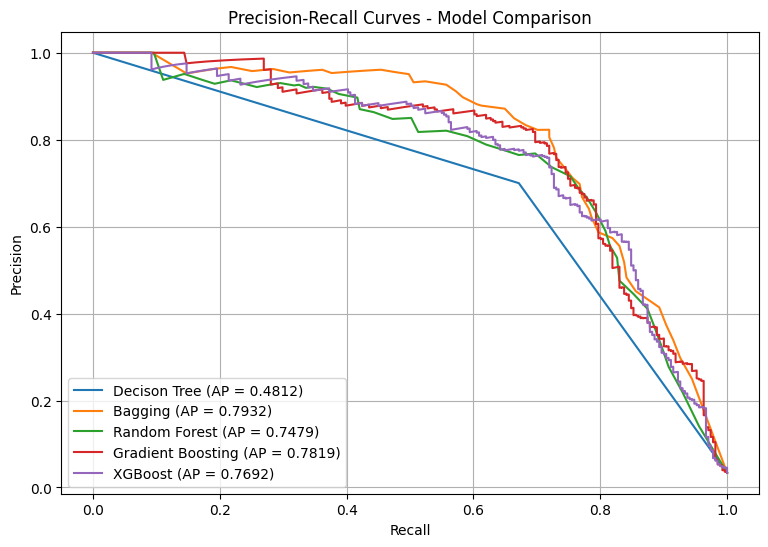

In [541]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(9, 6))

for name, model in models.items():

    y_proba = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_train, y_proba
    )

    ap_score = average_precision_score(y_train, y_proba)

    plt.plot(
        recall,
        precision,
        label=f'{name} (AP = {ap_score:.4f})'
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves - Model Comparison')
plt.legend()
plt.grid()
plt.show()

Bagging has the highest AP, followed closely by Gradient Boosting and XGBoost.

Decision Tree's AP of 0.4812 is considerably lower. It is struggling to maintain good precision as recall increases.

In [542]:
threshold_df.sort_values(by='Recall',ascending=False)

,Model,Threshold,Precision,Recall,F1,FPR
6,Bagging,0.2,0.573643,0.819188,0.674772,0.021348
24,Random Forest,0.2,0.555276,0.815498,0.660688,0.022901
12,Gradient Boosting,0.2,0.673077,0.774908,0.720412,0.013197
7,Bagging,0.3,0.697987,0.767528,0.731107,0.011644
25,Random Forest,0.3,0.715789,0.752768,0.733813,0.010480
18,XGBoost,0.2,0.664474,0.745387,0.702609,0.013197
19,XGBoost,0.3,0.738636,0.719557,0.728972,0.008927
13,Gradient Boosting,0.3,0.780000,0.719557,0.748560,0.007116
8,Bagging,0.4,0.805785,0.719557,0.760234,0.006081
20,XGBoost,0.4,0.769874,0.678967,0.721569,0.007116


Bagging at 0.2 threshld has highest recall around 81 % and around 57% precesion. and the FPR which is the model predicting the false class incorrectlty as  postive ones is around 2 % . 



In [ ]:
threshold_df.sort_values(by='FPR',ascending=False)

# so at 0.2 Random forest  produce the least FPR . 

,Model,Threshold,Precision,Recall,F1,FPR
24,Random Forest,0.2,0.555276,0.815498,0.660688,0.022901
6,Bagging,0.2,0.573643,0.819188,0.674772,0.021348
18,XGBoost,0.2,0.664474,0.745387,0.702609,0.013197
12,Gradient Boosting,0.2,0.673077,0.774908,0.720412,0.013197
7,Bagging,0.3,0.697987,0.767528,0.731107,0.011644
25,Random Forest,0.3,0.715789,0.752768,0.733813,0.010480
0,Decision Tree,0.2,0.700000,0.671587,0.685499,0.010092
1,Decision Tree,0.3,0.700000,0.671587,0.685499,0.010092
2,Decision Tree,0.4,0.700000,0.671587,0.685499,0.010092
3,Decision Tree,0.5,0.700000,0.671587,0.685499,0.010092


In [544]:
# F1 is the harmonic mean of precision and recall. 
# it balances precsion and recall 

threshold_df.sort_values(
    by='F1',
    ascending=False
)

,Model,Threshold,Precision,Recall,F1,FPR
8,Bagging,0.4,0.805785,0.719557,0.760234,0.006081
13,Gradient Boosting,0.3,0.780000,0.719557,0.748560,0.007116
9,Bagging,0.5,0.871287,0.649446,0.744186,0.003364
14,Gradient Boosting,0.4,0.830275,0.667897,0.740286,0.004787
25,Random Forest,0.3,0.715789,0.752768,0.733813,0.010480
7,Bagging,0.3,0.697987,0.767528,0.731107,0.011644
19,XGBoost,0.3,0.738636,0.719557,0.728972,0.008927
20,XGBoost,0.4,0.769874,0.678967,0.721569,0.007116
12,Gradient Boosting,0.2,0.673077,0.774908,0.720412,0.013197
15,Gradient Boosting,0.5,0.867021,0.601476,0.710240,0.003235


At threshold 0.4, Bagging achieves:
- Precision: 80.6%
- Recall: 72%
- F1: 76%
- FPR: 0.61%
This is the strongest balance between precision and recall in your table.


In [545]:

# 1. Best overall balance
threshold_df.loc[threshold_df['F1'].idxmax()]


Model         Bagging
Threshold         0.4
Precision    0.805785
Recall       0.719557
F1           0.760234
FPR          0.006081
Name: 8, dtype: object

In [546]:
# 2. Highest recall
threshold_df.loc[threshold_df['Recall'].idxmax()]

Model         Bagging
Threshold         0.2
Precision    0.573643
Recall       0.819188
F1           0.674772
FPR          0.021348
Name: 6, dtype: object

In [547]:

# 3. Highest precision with minimum 75% recall

threshold_df[
    threshold_df['Recall'] >= 0.75
].sort_values(
    by='Precision',
    ascending=False
).head(1)

,Model,Threshold,Precision,Recall,F1,FPR
25,Random Forest,0.3,0.715789,0.752768,0.733813,0.01048


Determing the best model i.e either we should choose the model with the highest recall or the model which has balance between precision , recall less FPR depends purely on the Business probelm we are solving . 

> So for our situation , we want model that accurately predicts failure , and dosent generate false alarm by predecting healthy machine as failure which can cause unnecessary maintainace cost . So we will go along with the Balanced one . 

